## Part 2: Unguided Exercise - Customer Churn Prediction

### Background

Now it's your turn! You'll work independently to predict customer churn for a telecommunications company. Customer churn is when customers stop using a company's services. Predicting churn helps companies take proactive measures to retain customers.

**Dataset:** Telco Customer Churn Dataset
- **Source:** [Kaggle - Telco Customer Churn](https://www.kaggle.com/datasets/blastchar/telco-customer-churn)

**Dataset Description:**
- Contains information about 7,043 customers
- Features include: customer demographics, services subscribed, account information
- Target: Whether the customer churned (Yes/No)


#### Step 1: Load and Explore the Data
- Download the Telco Customer Churn dataset
- Load it into a pandas DataFrame
- Explore the dataset: shape, columns, data types, missing values
- Check the target distribution (how many churned vs. didn't churn)
- Visualize some key features

In [3]:
%pip install kagglehub


   ---------------------------------------- 0/3 [protobuf]
   ---------------------------------------- 0/3 [protobuf]
   ------------- -------------------------- 1/3 [kagglesdk]
   ------------- -------------------------- 1/3 [kagglesdk]
   ------------- -------------------------- 1/3 [kagglesdk]
   ------------- -------------------------- 1/3 [kagglesdk]
   ------------- -------------------------- 1/3 [kagglesdk]
   ------------- -------------------------- 1/3 [kagglesdk]
   -------------------------- ------------- 2/3 [kagglehub]
   ---------------------------------------- 3/3 [kagglehub]

Note: you may need to restart the kernel to use updated packages.


In [4]:
import kagglehub
import pandas as pd
from pathlib import Path

# 1. Download the dataset
path = kagglehub.dataset_download("blastchar/telco-customer-churn")

print("Dataset downloaded to:", path)

# 2. Locate the CSV file
csv_file = Path(path) / "WA_Fn-UseC_-Telco-Customer-Churn.csv"

# 3. Load into pandas
df = pd.read_csv(csv_file)

# 4. Verify
print("Dataset shape:", df.shape)
print(df.head())

c:\Users\sabri\miniconda3\envs\bootcamp-env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


100%|██████████| 172k/172k [00:00<00:00, 810kB/s]

Extracting files...
Dataset downloaded to: C:\Users\sabri\.cache\kagglehub\datasets\blastchar\telco-customer-churn\versions\1
Dataset shape: (7043, 21)
   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...        

In [ ]:
# Check the target distribution (how many churned vs. didn't churn)

# Count customers by churn status
print("Churn distribution:")
print(df["Churn"].value_counts())

# Calculate percentages
print("\nChurn percentages:")
print(df["Churn"].value_counts(normalize=True) * 100)

Churn distribution:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn percentages:
Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


**Interpretation:** Approximately 1 in 4 customers churned.
This matters because the dataset is imbalanced: the model will see more examples of customers staying than leaving. Later, we'll need to consider this when evaluating accuracy and recall.

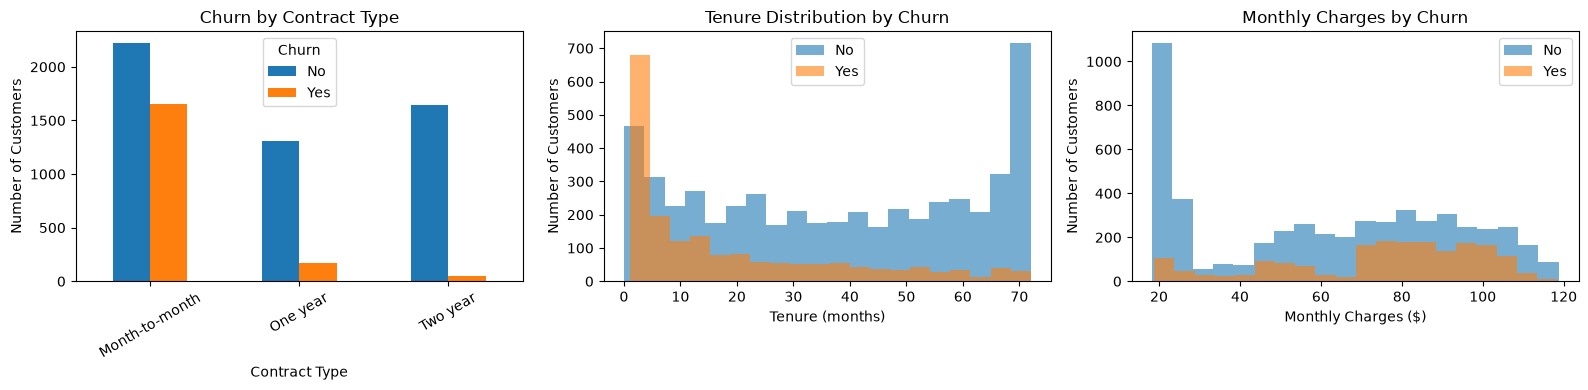

In [6]:
# Visualize key features: Explore whether customer characteristics differ between customers who stayed and those who churned.
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# 1. Contract type vs Churn
pd.crosstab(df["Contract"], df["Churn"]).plot(
    kind="bar",
    ax=axes[0]
)
axes[0].set_title("Churn by Contract Type")
axes[0].set_xlabel("Contract Type")
axes[0].set_ylabel("Number of Customers")
axes[0].tick_params(axis="x", rotation=30)

# 2. Tenure vs Churn
for churn_status in ["No", "Yes"]:
    axes[1].hist(
        df[df["Churn"] == churn_status]["tenure"],
        bins=20,
        alpha=0.6,
        label=churn_status
    )
axes[1].set_title("Tenure Distribution by Churn")
axes[1].set_xlabel("Tenure (months)")
axes[1].set_ylabel("Number of Customers")
axes[1].legend()

# 3. Monthly Charges vs Churn
for churn_status in ["No", "Yes"]:
    axes[2].hist(
        df[df["Churn"] == churn_status]["MonthlyCharges"],
        bins=20,
        alpha=0.6,
        label=churn_status
    )
axes[2].set_title("Monthly Charges by Churn")
axes[2].set_xlabel("Monthly Charges ($)")
axes[2].set_ylabel("Number of Customers")
axes[2].legend()

plt.tight_layout()
plt.show()

In [7]:
# Calculate churn rate by contract type
churn_rate = pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
) * 100

print(churn_rate.round(2))

Churn              No    Yes
Contract                    
Month-to-month  57.29  42.71
One year        88.73  11.27
Two year        97.17   2.83


Churn rate by tenure:
TenureGroup
0-12     47.44
13-24    28.71
25-36    21.63
37-48    19.03
49-60    14.42
61-72     6.61
Name: Churn, dtype: float64


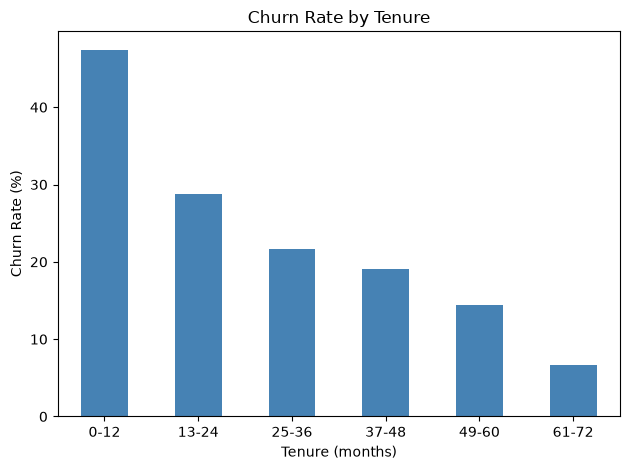

In [8]:
# Create tenure groups
df["TenureGroup"] = pd.cut(
    df["tenure"],
    bins=[-1, 12, 24, 36, 48, 60, 72],
    labels=["0-12", "13-24", "25-36", "37-48", "49-60", "61-72"]
)

# Calculate churn rate by tenure group
tenure_churn = (
    df.groupby("TenureGroup", observed=True)["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
)

print("Churn rate by tenure:")
print(tenure_churn.round(2))

# Visualize
tenure_churn.plot(kind="bar", color="steelblue")

plt.title("Churn Rate by Tenure")
plt.xlabel("Tenure (months)")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Churn rate by monthly charges:
ChargesGroup
0-40      11.64
40-60     25.56
60-80     32.42
80-100    37.02
100+      28.05
Name: Churn, dtype: float64


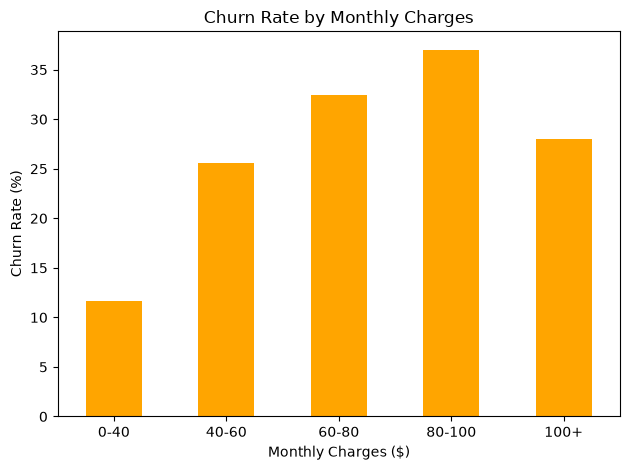

In [9]:
# Create monthly charge groups
df["ChargesGroup"] = pd.cut(
    df["MonthlyCharges"],
    bins=[0, 40, 60, 80, 100, float("inf")],
    labels=["0-40", "40-60", "60-80", "80-100", "100+"],
    include_lowest=True
)

# Calculate churn rate by charge group
charges_churn = (
    df.groupby("ChargesGroup", observed=True)["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
)

print("Churn rate by monthly charges:")
print(charges_churn.round(2))

# Visualize
charges_churn.plot(kind="bar", color="orange")

plt.title("Churn Rate by Monthly Charges")
plt.xlabel("Monthly Charges ($)")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

#### Step 2: Data Preprocessing
- Handle missing values (if any)
- Convert categorical variables to numeric (use encoding techniques)
- Select relevant features for modeling
- Separate features (X) from target (y)
- Convert target to binary (0/1) if needed

In [10]:
# Check missing values in all columns
print("Missing values before cleaning:")
print(df.isnull().sum())

# Convert TotalCharges to numeric
# Empty or invalid values become NaN
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

# Check missing values again
print("\nMissing values after conversion:")
print(df.isnull().sum())

# Count missing TotalCharges values
print("\nMissing TotalCharges:", df["TotalCharges"].isnull().sum())

Missing values before cleaning:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
TenureGroup         0
ChargesGroup        0
dtype: int64

Missing values after conversion:
customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
M

In [11]:
# Remove rows with missing TotalCharges
df = df.dropna(subset=["TotalCharges"]).copy()

# Verify
print("Dataset shape after cleaning:", df.shape)
print("Remaining missing values:", df.isnull().sum().sum())

Dataset shape after cleaning: (7032, 23)
Remaining missing values: 0


In [12]:
# Remove the temporary columns created for visualization
df = df.drop(columns=["TenureGroup", "ChargesGroup"])

# Identify categorical columns
categorical_cols = df.select_dtypes(include=["object", "category"]).columns.tolist()

print("Categorical columns:")
print(categorical_cols)

# Exclude customer ID and target from encoding
categorical_features = [
    col for col in categorical_cols
    if col not in ["customerID", "Churn"]
]

# Convert categorical features to numerical columns
df_encoded = pd.get_dummies(
    df,
    columns=categorical_features,
    drop_first=True,
    dtype=int
)

print("\nEncoded dataset shape:", df_encoded.shape)
print("\nFirst 5 rows:")
print(df_encoded.head())

Categorical columns:
['customerID', 'gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'Churn']

Encoded dataset shape: (7032, 32)

First 5 rows:
   customerID  SeniorCitizen  tenure  MonthlyCharges  TotalCharges Churn  \
0  7590-VHVEG              0       1           29.85         29.85    No   
1  5575-GNVDE              0      34           56.95       1889.50    No   
2  3668-QPYBK              0       2           53.85        108.15   Yes   
3  7795-CFOCW              0      45           42.30       1840.75    No   
4  9237-HQITU              0       2           70.70        151.65   Yes   

   gender_Male  Partner_Yes  Dependents_Yes  PhoneService_Yes  ...  \
0            0            1               0                 0  ...   
1            1            0               0                 1  ...   

C:\Users\sabri\AppData\Local\Temp\ipykernel_19712\4096045961.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df.select_dtypes(include=["object", "category"]).columns.tolist()


In [13]:
# Remove customerID because it is only an identifier
df_model = df_encoded.drop(columns=["customerID"])

# Check the remaining columns
print("Dataset shape:", df_model.shape)
print("\nColumns selected for modeling:")
print(df_model.columns.tolist())

Dataset shape: (7032, 31)

Columns selected for modeling:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges', 'Churn', 'gender_Male', 'Partner_Yes', 'Dependents_Yes', 'PhoneService_Yes', 'MultipleLines_No phone service', 'MultipleLines_Yes', 'InternetService_Fiber optic', 'InternetService_No', 'OnlineSecurity_No internet service', 'OnlineSecurity_Yes', 'OnlineBackup_No internet service', 'OnlineBackup_Yes', 'DeviceProtection_No internet service', 'DeviceProtection_Yes', 'TechSupport_No internet service', 'TechSupport_Yes', 'StreamingTV_No internet service', 'StreamingTV_Yes', 'StreamingMovies_No internet service', 'StreamingMovies_Yes', 'Contract_One year', 'Contract_Two year', 'PaperlessBilling_Yes', 'PaymentMethod_Credit card (automatic)', 'PaymentMethod_Electronic check', 'PaymentMethod_Mailed check']


In [14]:
# Features: all columns except Churn
X = df_model.drop(columns=["Churn"])

# Target: Churn column
y = df_model["Churn"]

# Verify
print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nTarget values:")
print(y.value_counts())

X shape: (7032, 30)
y shape: (7032,)

Target values:
Churn
No     5163
Yes    1869
Name: count, dtype: int64


In [15]:
# Convert target values to binary
y = y.map({"No": 0, "Yes": 1})

# Verify the conversion
print("Target distribution:")
print(y.value_counts())

# Check for missing values after conversion
print("\nMissing target values:", y.isnull().sum())

Target distribution:
Churn
0    5163
1    1869
Name: count, dtype: int64

Missing target values: 0


#### Step 3: Split the Data
- Split into training (80%) and testing (20%) sets
- Use `stratify` to maintain class distribution
- Set `random_state=42` for reproducibility

In [16]:
from sklearn.model_selection import train_test_split

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

# Verify the split
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (5625, 30)
X_test shape: (1407, 30)
y_train shape: (5625,)
y_test shape: (1407,)


In [17]:
print("Original churn distribution (%):")
print(y.value_counts(normalize=True) * 100)

print("\nTraining churn distribution (%):")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting churn distribution (%):")
print(y_test.value_counts(normalize=True) * 100)

Original churn distribution (%):
Churn
0    73.421502
1    26.578498
Name: proportion, dtype: float64

Training churn distribution (%):
Churn
0    73.422222
1    26.577778
Name: proportion, dtype: float64

Testing churn distribution (%):
Churn
0    73.418621
1    26.581379
Name: proportion, dtype: float64


In [18]:
from sklearn.preprocessing import StandardScaler

# Create the scaler
scaler = StandardScaler()

# Learn scaling parameters from training data only
X_train_scaled = scaler.fit_transform(X_train)

# Apply the same transformation to test data
X_test_scaled = scaler.transform(X_test)

print("Training data shape:", X_train_scaled.shape)
print("Testing data shape:", X_test_scaled.shape)

Training data shape: (5625, 30)
Testing data shape: (1407, 30)


#### Step 4: Train a KNN Model
- Create a KNN classifier
- Start with `n_neighbors=5`
- Train the model on the training data

In [19]:
from sklearn.neighbors import KNeighborsClassifier

# Create KNN classifier
knn = KNeighborsClassifier(n_neighbors=5)

# Train the model
knn.fit(X_train_scaled, y_train)

print("KNN model trained successfully!")

KNN model trained successfully!


#### Step 5: Make Predictions and Evaluate
- Make predictions on the test set
- Calculate accuracy, precision, and recall
- Create a confusion matrix
- Generate a classification report
- Interpret the results

In [20]:
# Predict churn for customers in the test set
y_pred = knn.predict(X_test_scaled)

# Display the first 10 predictions
print("Predicted values:", y_pred[:10])
print("Actual values:   ", y_test.to_numpy()[:10])

Predicted values: [0 1 0 0 0 1 0 0 1 0]
Actual values:    [0 0 0 1 0 1 0 0 1 0]


In [21]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    classification_report,
    confusion_matrix
)

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)

print(f"Accuracy:  {accuracy:.2%}")
print(f"Precision: {precision:.2%}")
print(f"Recall:    {recall:.2%}")

# Detailed classification report
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Stayed", "Churned"]
))

Accuracy:  75.34%
Precision: 53.62%
Recall:    53.48%

Classification Report:
              precision    recall  f1-score   support

      Stayed       0.83      0.83      0.83      1033
     Churned       0.54      0.53      0.54       374

    accuracy                           0.75      1407
   macro avg       0.68      0.68      0.68      1407
weighted avg       0.75      0.75      0.75      1407



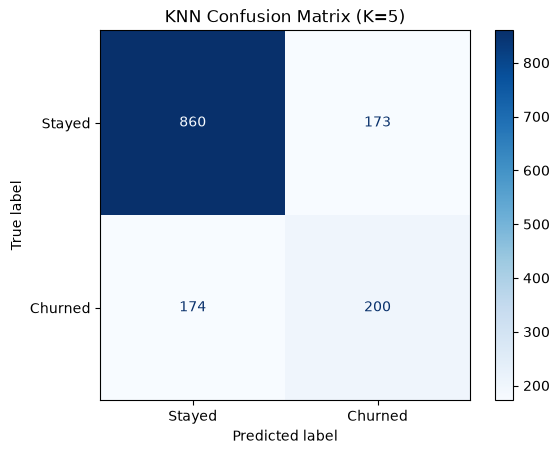

In [22]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["Stayed", "Churned"],
    cmap="Blues",
    values_format="d"
)

plt.title("KNN Confusion Matrix (K=5)")
plt.show()

Consulting conclusion
The model shows some predictive value, but these results are not yet sufficient to recommend deploying it for retention decisions. We need to understand the cost of missed churners, unnecessary retention offers, and whether another model configuration performs better.

#### Step 6: Experiment and Improve
- Try different K values (1, 3, 5, 7, 9, 11, 15)
- Compare their performance
- Choose the best K value
- Document your findings

In [36]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
import pandas as pd

k_values = [1, 3, 5, 7, 9, 11, 15]
results = []

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

for k in k_values:
    model = make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=k)
    )

    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring="recall"
    )

    results.append({
        "K": k,
        "Mean Recall": scores.mean(),
        "Std Recall": scores.std()
    })

results_df = pd.DataFrame(results)

print(results_df.round(3))

    K  Mean Recall  Std Recall
0   1        0.490       0.009
1   3        0.507       0.030
2   5        0.522       0.014
3   7        0.525       0.009
4   9        0.551       0.017
5  11        0.554       0.005
6  15        0.573       0.010


In [37]:
# Train the selected KNN model
knn_15 = KNeighborsClassifier(n_neighbors=15)
knn_15.fit(X_train_scaled, y_train)

# Make predictions
y_pred_15 = knn_15.predict(X_test_scaled)

# Evaluate
print("KNN with K = 15")
print(f"Accuracy:  {accuracy_score(y_test, y_pred_15):.2%}")
print(f"Precision: {precision_score(y_test, y_pred_15):.2%}")
print(f"Recall:    {recall_score(y_test, y_pred_15):.2%}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_15,
    target_names=["Stayed", "Churned"]
))

KNN with K = 15
Accuracy:  77.11%
Precision: 57.34%
Recall:    54.28%

Classification Report:
              precision    recall  f1-score   support

      Stayed       0.84      0.85      0.85      1033
     Churned       0.57      0.54      0.56       374

    accuracy                           0.77      1407
   macro avg       0.71      0.70      0.70      1407
weighted avg       0.77      0.77      0.77      1407



Step 6 conclusion
For this lab, K = 15 is the preferred configuration among those tested, because it achieved the highest mean cross-validation recall and improved all three metrics on the held-out test set.
However, this is not evidence that K = 15 is globally optimal, or that the model is ready for production.

##Before recommending retention offers, we should estimate the financial consequences of the model's errors:

In [38]:
from sklearn.metrics import confusion_matrix

tn, fp, fn, tp = confusion_matrix(y_test, y_pred_15).ravel()

print("True positives:", tp)
print("False positives:", fp)
print("False negatives:", fn)
print("True negatives:", tn)

True positives: 203
False positives: 151
False negatives: 171
True negatives: 882


#**Calculate the costs using K = 15**

In [39]:
offer_cost = 20

# Cost of offers sent to customers who would have stayed
false_positive_cost = fp * offer_cost

# Cost of offers sent to correctly identified churners
true_positive_offer_cost = tp * offer_cost

# Total cost of sending offers to all predicted churners
total_offer_cost = (tp + fp) * offer_cost

print(f"False positive offer cost: €{false_positive_cost:,.2f}")
print(f"True positive offer cost: €{true_positive_offer_cost:,.2f}")
print(f"Total retention campaign cost: €{total_offer_cost:,.2f}")

False positive offer cost: €3,020.00
True positive offer cost: €4,060.00
Total retention campaign cost: €7,080.00


**Estimate the cost of missed churners:**

In [40]:
monthly_margin = 30       # Assumption
remaining_months = 12     # Assumption

lost_value_per_customer = monthly_margin * remaining_months
false_negative_cost = fn * lost_value_per_customer

print(f"Estimated cost of missed churners: €{false_negative_cost:,.2f}")

Estimated cost of missed churners: €61,560.00


## Step 7: Analysis and Recommendations

### 1. What is the model's accuracy?

The initial K-Nearest Neighbors (KNN) model, using **K = 5**, achieved an accuracy of **75.34%**.

I tested seven different K values (1, 3, 5, 7, 9, 11, and 15) using 5-fold stratified cross-validation on the training dataset. I compared their average recall scores because identifying customers who are likely to churn was the main priority.

K = 15 achieved the highest average recall (57.3%) among the tested values, compared with 52.2% for K = 5. I therefore selected K = 15 and evaluated it on the separate test dataset, where it achieved 77.11% accuracy, 57.34% precision, and 54.28% recall.

K = 15 was the best option **among the values tested**, but this does not mean it is the optimal K for every situation. Further experimentation and consideration of business costs would be needed before deployment.

The final model achieved:

| Metric | K = 5 | K = 15 |
|---|---:|---:|
| Accuracy | 75.34% | **77.11%** |
| Precision (Churn) | 53.62% | **57.34%** |
| Recall (Churn) | 53.48% | **54.28%** |

Although K = 15 improved overall performance, the model still failed to identify approximately 46% of customers who actually churned.

Accuracy alone is not sufficient to evaluate this model because the dataset is imbalanced: approximately 73% of customers did not churn.

### 2. What features seem most important?

Based on the exploratory data analysis, three features appear particularly relevant to customer churn:

- **Contract type:** Customers with month-to-month contracts showed higher churn rates than customers with one-year or two-year contracts.
- **Tenure:** Customers who had been with the company for a shorter period appeared more likely to churn than long-term customers.
- **Monthly charges:** Monthly charges were explored as a possible factor associated with churn, although their relative importance has not been established.

These observations suggest that contract type and tenure may be useful predictors of customer churn.

However, the analysis identifies associations, not causal relationships. Additionally, KNN does not directly provide feature importance scores, so further analysis would be necessary to determine which variables contribute most to its predictions.

### 3. What would you recommend to the company based on your model?

I would recommend using the model as an initial tool to support customer retention analysis, rather than immediately deploying an automated retention campaign.

The company should:

1. **Investigate high-risk customer segments**, particularly customers with month-to-month contracts and shorter tenure.
2. **Analyze the reasons behind customer churn**, including service quality, pricing, customer experience, and contract conditions.
3. **Test retention interventions** through controlled experiments to determine whether discounts, improved support, or other actions actually reduce churn.
4. **Evaluate financial impact** by comparing intervention costs with the expected value of customers retained.
5. **Improve and validate the predictive model** before integrating it into operational retention workflows.

A key consideration is that predicting churn does not automatically prevent it. The company needs to identify interventions that measurably change customer behavior.

### 4. What are the limitations of your model?

The KNN model has several limitations:

- **Moderate predictive performance:** With 77.11% accuracy and 54.28% churn recall, the model still misses a substantial proportion of customers who leave.
- **Class imbalance:** Approximately 73% of customers stayed, which makes accuracy potentially misleading.
- **Sensitivity to feature scaling:** KNN relies on distance calculations, so numerical features must be scaled appropriately.
- **Limited interpretability:** KNN does not directly explain which features drive individual predictions.
- **Limited hyperparameter exploration:** Only a small selection of K values was tested. Other settings and algorithms might perform better.
- **No causal evidence:** The model identifies patterns associated with churn but cannot explain why customers leave or whether retention offers will work.
- **Limited generalizability:** Performance was evaluated on a historical dataset and may change with new customers, changing market conditions, or different customer populations.

### Conclusion

The KNN model provides a useful starting point for identifying customers at risk of churn. Increasing K from 5 to 15 improved accuracy and precision, but churn recall remained relatively low.

I would not recommend deploying the model as the sole basis for retention decisions. Instead, the company should combine predictive analysis with customer research, controlled retention experiments, financial evaluation, and ongoing model monitoring.

**The objective should not simply be to predict churn accurately, but to reduce preventable churn in a measurable and cost-effective way.**